# Ordinační analýza I.
* Co je to ordinační analýza?

## Cíle cvičení:
* Naučit se jednotlivé kroky analýzy hlavních komponent (Principal Component Analysis):
    * Prvotní analýza dostupných dat a jejich úprava
    * Testování předpokladů a podmínek
    * Implementace PCA
    * Interpretace výsledků PCA
    * Využití PCA pro klasifikaci/predikci


## Obsah cvičení:
* Importy knihoven a balíčků
* Mapování dat
* Výpočet korelačních a kovariančních matic (kovarianční matice je jako korelační, ale na STDovaných datech)
* Spektrální rozklad
* Ověření ortonormality vlastních vektorů
* Stanovení optimálního počtu hlavních komponent (K)
* Výběr K transformačních vektorů
* Výpočet hlavních komponent
* Verifikace nezávislosti hlavních komponent
* Vizuální analýza výstupu PCA
* Predikční model pomocí logistické regrese

## Užitečné odkazy
* PCA: https://towardsdatascience.com/a-one-stop-shop-for-principal-component-analysis-5582fb7e0a9c
* PCA in 3 steps: https://sebastianraschka.com/Articles/2015_pca_in_3_steps.html
* https://www.projectrhea.org/rhea/index.php/PCA_Theory_Examples

* Paper describing dataset: https://bmccancer.biomedcentral.com/articles/10.1186/s12885-017-3877-1

* PCA from scratch in Python: https://towardsdatascience.com/principal-component-analysis-pca-from-scratch-in-python-7f3e2a540c51



## Importy knihoven a balíčků

In [ ]:
from google.colab import drive
from os import listdir
from os.path import isfile, join
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler

## Mapování dat


In [ ]:
# Mount drive with data paths
drive.mount("/content/drive", force_remount=True)


Mounted at /content/drive


In [ ]:
root_dir ="/content/drive/MyDrive/VMM/cviceni_05/"
base_dir = root_dir

data_path = base_dir + ""

In [ ]:
# Load data for analysis from csv file
data_DF_orig = pd.read_csv(f'{data_path}cviceni6_data.csv', sep=",")

data_DF_orig.head()
#print(data_DF)

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114,1
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786,1
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697,1
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220,1
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920,1


In [ ]:
# create subset of dataset without categorical features
data_DF = data_DF_orig.drop(["Classification"], axis=1)
data_DF.head()

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920


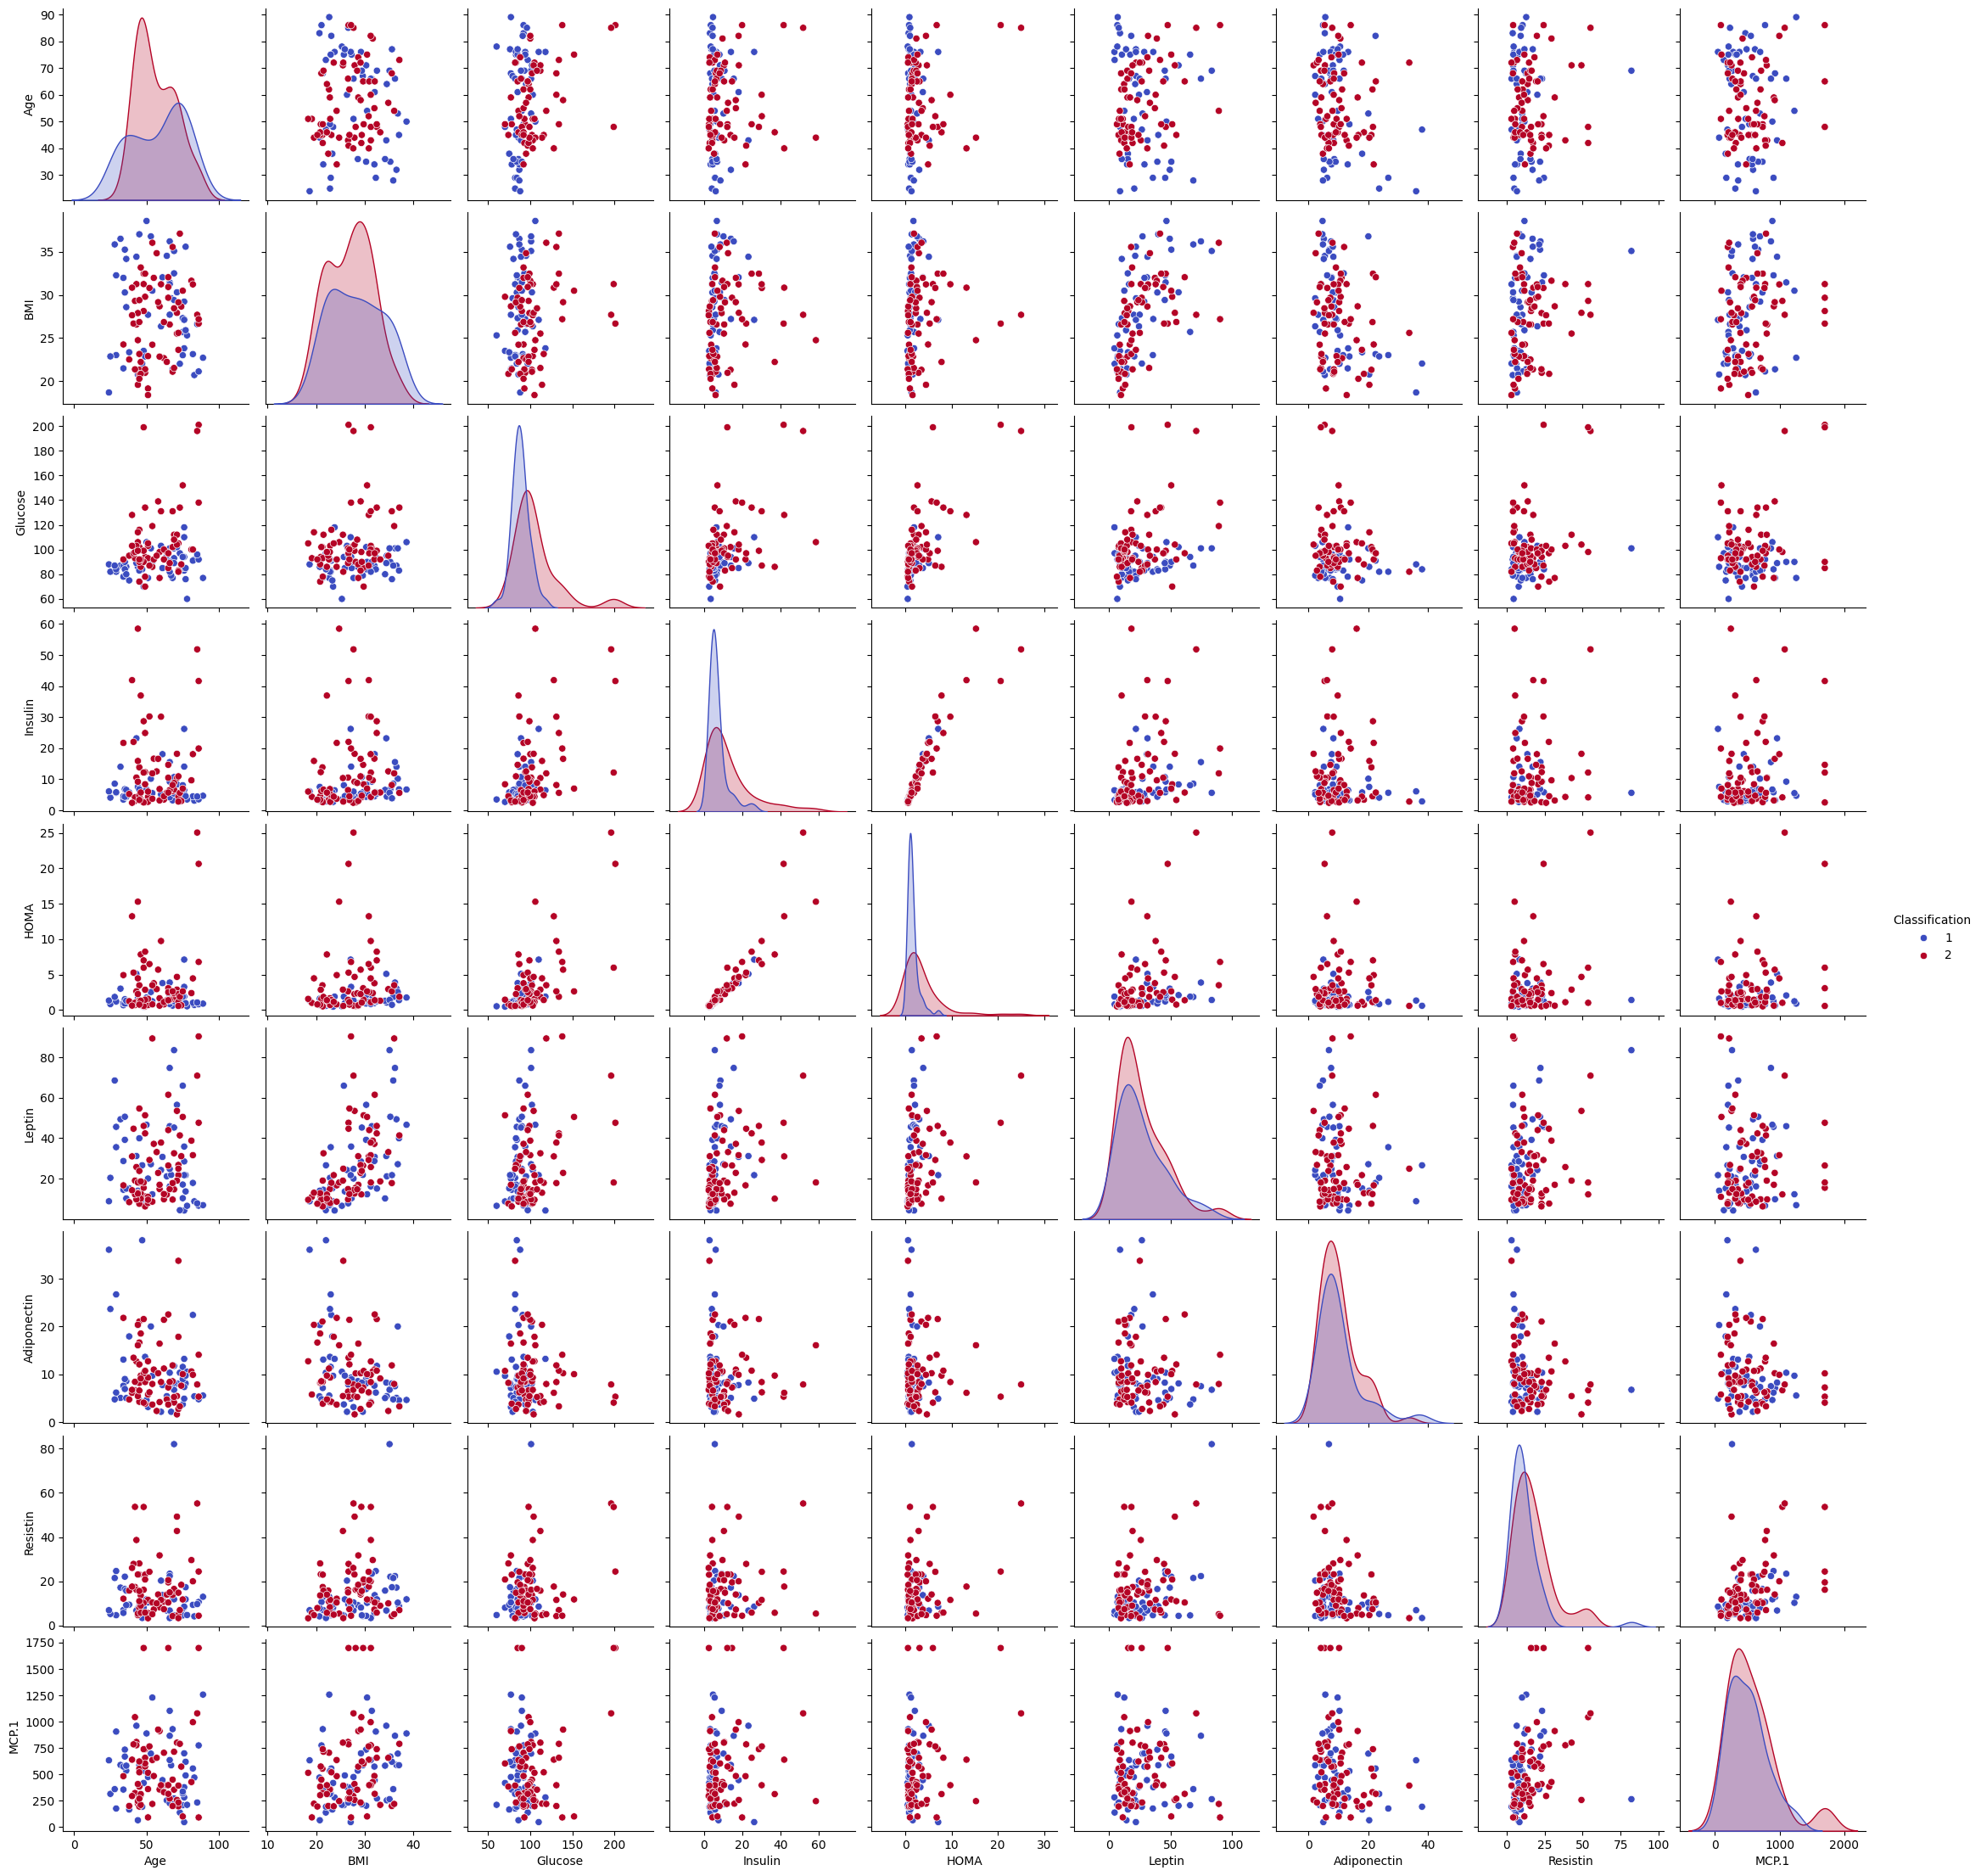

In [ ]:
# create pairplot graph for all the original data, use different colours for healthy/ill objects
sns.pairplot(data_DF_orig, palette="coolwarm", hue="Classification")

Odpovězte:

1. Jsou splněny podmínky pro PCA?
  - Ano, protože pracujeme s kvantitativními spojitými daty, kde mezi proměnnými existují vzájemné lineární korelace.
2. Je nutné data standardizovat?
  - Spíše ano, jelikož měříme veličiny v úplně jiných jednotkách a škálách, což by bez škálování nespravedlivě zvýhodnilo jen proměnné s největšími čísly, pokud bychom měli veličiny se stejným měřítkem, např. v mm, tak škálování nutné není (ale to se nestává).
3. Okomentujte rozložení hodnot jednotlivých parametrů.
  - Většina parametrů má zešikmené rozdělení s extrémy (např. inzulin) nebo nelogickými nulami místo chybějících měření (např. tlak a BMI).
4. Intuitivně vyberte příznaky, které považujete důležité pro klasifikaci.
glukoza, inzulin,
  - Kromě glukózy a inzulinu jsou nejdůležitější BMI a věk jakožto hlavní medicínské rizikové faktory cukrovky.
5. Jaké příznaky by měly být vybrány pomocí PCA (jejich vlastnosti)?
  - PCA vybere a sloučí ty příznaky, které mezi sebou silně korelují a nesou největší společnou variabilitu (rozptyl).
6. Jaký je rozdíl mezi výběrem důležitých příznaků pro klasifikaci a PCA?
  - PCA hledá proměnné s největším rozptylem zcela naslepo bez ohledu na diagnózu, zatímco výběr pro klasifikaci hledá proměnné, které nejlépe odliší nemocné od zdravých.

## Výpočet korelační/kovarianční matice

[[ 1.00869565  0.00860403  0.23210654  0.03277792  0.12813722  0.10351845
  -0.22172431  0.00276555  0.01357874]
 [ 0.00860403  1.00869565  0.14005254  0.1465587   0.11547561  0.57454559
  -0.30536723  0.1970489   0.22598637]
 [ 0.23210654  0.14005254  1.00869565  0.50904136  0.70226584  0.3077328
  -0.12318324  0.29386074  0.26718257]
 [ 0.03277792  0.1465587   0.50904136  1.00869565  0.94030383  0.30408302
  -0.03156822  0.14800691  0.17587194]
 [ 0.12813722  0.11547561  0.70226584  0.94030383  1.00869565  0.33005517
  -0.05682701  0.23311081  0.26178596]
 [ 0.10351845  0.57454559  0.3077328   0.30408302  0.33005517  1.00869565
  -0.09621821  0.25846164  0.01413044]
 [-0.22172431 -0.30536723 -0.12318324 -0.03156822 -0.05682701 -0.09621821
   1.00869565 -0.25455777 -0.20243967]
 [ 0.00276555  0.1970489   0.29386074  0.14800691  0.23311081  0.25846164
  -0.25455777  1.00869565  0.36966094]
 [ 0.01357874  0.22598637  0.26718257  0.17587194  0.26178596  0.01413044
  -0.20243967  0.369660

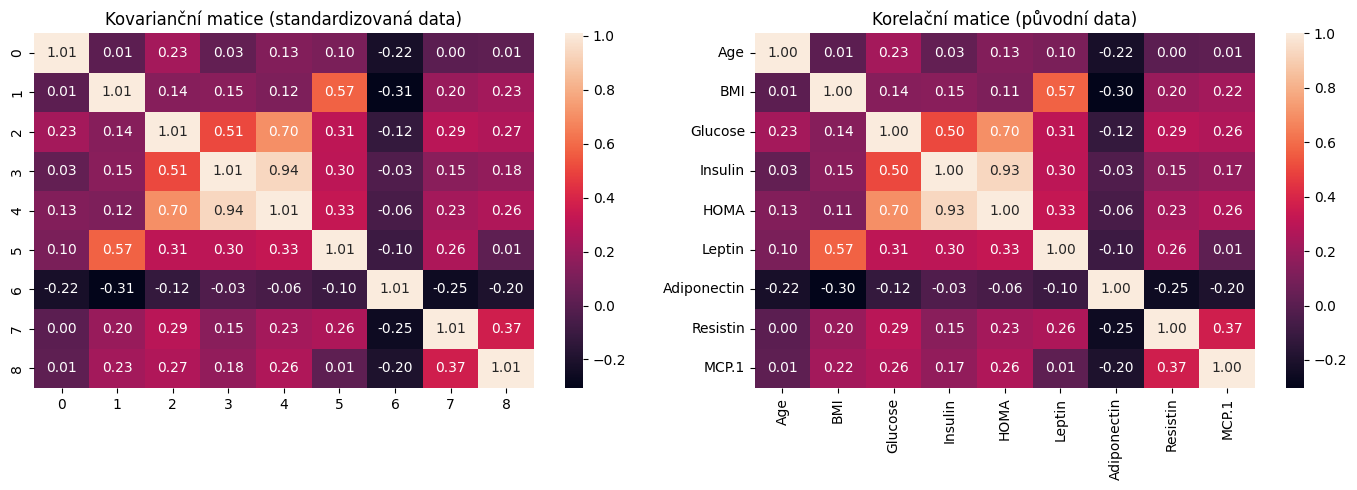

In [ ]:
# covariance matrix on standardized data
standard = StandardScaler()
data_stand = standard.fit_transform(data_DF)
covariance_matrix = np.cov(data_stand.T)  # opraveno: posíláme data_stand.T místo data_DF.T
print(covariance_matrix)

# correlation matrix on original data
correlation_matrix = data_DF.corr()
print(correlation_matrix)

# Vykreslení vedle sebe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(covariance_matrix, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("Kovarianční matice (standardizovaná data)")

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Korelační matice (původní data)")

plt.tight_layout()
plt.show()

1. Má smysl na tento dataset aplikovat metodu PCA? Zdůvodněte.
  - Ano, protože mezi proměnnými existují statisticky významné vzájemné korelace (např. inzulin–glukóza, věk–těhotenství, BMI–tloušťka kůže), což znamená přítomnost redundance, kterou dokáže PCA efektivně komprimovat do menšího počtu nekorelovaných os.
2. Popište získané matice a vztahy uvnitř nich.
  - Obě matice jsou čtvercové, symetrické s jedničkami na hlavní diagonále a numericky totožné, protože kovariance standardizovaných dat odpovídá korelaci. Zobrazují převážně slabé až středně silné pozitivní lineární vazby mezi příznaky a potvrzují, že data nesou sdílenou informaci.
3. Proč při odvozování hlavních komponent vycházíme z korelační/kovarianční matice?
  - Tyto matice matematicky vyjadřují celkovou variabilitu a společné kovariance v datech, což umožňuje spektrálním rozkladem (vlastní čísla a vlastní vektory) nalézt nové ortogonální směry s maximálním rozptylem.

Kovarianční matice standardizovaných dat je korelační maticí původních dat.

## Spektrální rozklad (eigendecomposition)
* Výpočet vlastních čísel a vektorů z korelačních/kovariančních matic

In [ ]:
# compute eigen values and vectors for dataset (using numpy)
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

idx = np.argsort(eigen_values)[::-1]
eigen_values = eigen_values[idx]
eigen_vectors = eigen_vectors[:, idx]

print("Vlastní čísla (seřazená):")
print(eigen_values)

print("\nVlastní vektory (sloupce matice):")
print(eigen_vectors)

Vlastní čísla (seřazená):
[3.08513568 1.53543777 1.17769636 1.11531287 0.72882532 0.66299464
 0.44539007 0.29516848 0.03229967]

Vlastní vektory (sloupce matice):
[[-0.12457393 -0.06626166  0.20670086  0.82138775  0.25297172  0.29483811
   0.30785182  0.12712772 -0.02879668]
 [-0.2604297  -0.49933879 -0.4257348  -0.07092159 -0.23245691  0.27652419
  -0.05332906  0.59945409  0.06217806]
 [-0.43902269  0.18594179  0.13088534  0.12561541  0.19951966  0.03011844
  -0.80716167  0.0844935  -0.20102285]
 [-0.44397869  0.38631334 -0.09371342 -0.05977182 -0.29761132 -0.12162117
   0.39056498  0.09436728 -0.61357938]
 [-0.49285171  0.37472788  0.01219108 -0.00564402 -0.1391521  -0.06763632
   0.13142043  0.01629459  0.75830133]
 [-0.33149346 -0.23364275 -0.5832015   0.05835395  0.28780589  0.02159401
   0.05409473 -0.63623826 -0.03114599]
 [ 0.17260956  0.4805981  -0.28212343 -0.27686688  0.52928424  0.48846279
   0.10252955  0.23175112 -0.00488958]
 [-0.28174128 -0.30361887  0.28892346 -0.30270

In [ ]:
# Make a list of (eigenvalue, eigenvector) tuples
eigen_pairs = [(np.abs(eigen_values[i]), eigen_vectors[:, i]) for i in range(len(eigen_values))]

# Sort the (eigenvalue, eigenvector) tuples from high to low
eigen_pairs.sort(key=lambda k: k[0], reverse=True)

# Výpis seřazených párů
print("Seřazené dvojice (vlastní číslo -> vlastní vektor):")
for i, pair in enumerate(eigen_pairs):
    print(f"\nKomponenta {i+1}:")
    print(f"  Vlastní číslo: {pair[0]:.4f}")
    print(f"  Vlastní vektor: {np.round(pair[1], 4)}")

Seřazené dvojice (vlastní číslo -> vlastní vektor):

Komponenta 1:
  Vlastní číslo: 3.0851
  Vlastní vektor: [-0.1246 -0.2604 -0.439  -0.444  -0.4929 -0.3315  0.1726 -0.2817 -0.2546]

Komponenta 2:
  Vlastní číslo: 1.5354
  Vlastní vektor: [-0.0663 -0.4993  0.1859  0.3863  0.3747 -0.2336  0.4806 -0.3036 -0.2104]

Komponenta 3:
  Vlastní číslo: 1.1777
  Vlastní vektor: [ 0.2067 -0.4257  0.1309 -0.0937  0.0122 -0.5832 -0.2821  0.2889  0.4968]

Komponenta 4:
  Vlastní číslo: 1.1153
  Vlastní vektor: [ 0.8214 -0.0709  0.1256 -0.0598 -0.0056  0.0584 -0.2769 -0.3027 -0.3595]

Komponenta 5:
  Vlastní číslo: 0.7288
  Vlastní vektor: [ 0.253  -0.2325  0.1995 -0.2976 -0.1392  0.2878  0.5293  0.5976 -0.1189]

Komponenta 6:
  Vlastní číslo: 0.6630
  Vlastní vektor: [ 0.2948  0.2765  0.0301 -0.1216 -0.0676  0.0216  0.4885 -0.4208  0.6326]

Komponenta 7:
  Vlastní číslo: 0.4454
  Vlastní vektor: [ 0.3079 -0.0533 -0.8072  0.3906  0.1314  0.0541  0.1025  0.2444  0.0889]

Komponenta 8:
  Vlastní číslo:

Odpovězte:
1. Jaký význam mají vlastní čísla a vektory v kontextu analýzy PCA?
  - Vlastní vektory určují směry nových ortogonálních os (hlavních komponent), zatímco vlastní čísla vyjadřují velikost rozptylu dat zachyceného podél těchto směrů.
2. Proč počítáme vlastní čísla a vektory z korelační/kovarianční matice, a ne z původních hodnot?
  - Kovarianční a korelační matice jsou čtvercové a symetrické a přímo kódují celkovou variabilitu a vzájemné vztahy mezi proměnnými, což je matematický předpoklad pro spektrální rozklad.

## Ověření ortonormality vlastních vektorů
* Všechny vlastní vektory jsou na sebe kolmé (ortogonální)
* Jejich vzájemný skalární součin je 0(pro různé vektory, tj. $v_i \cdot v_j = 0$ pro $i \neq j$), resp. 1 pro součin vektoru se sebou samým ($v_i \cdot v_i = 1$).
* Všechny vlastní vektory mají velikost 1 (normalita)


In [ ]:
# verify orthonormality of eigen vectors
ortho_matrix = np.dot(eigen_vectors.T, eigen_vectors)

print("V^T @ V (měla by být jednotková matice):")
print(np.round(ortho_matrix, decimals=4))

# 2. Programatická kontrola normality (délka = 1) a ortogonality (skalární součin = 0)
is_orthonormal = np.allclose(ortho_matrix, np.eye(len(eigen_values)))
print(f"\nJsou vlastní vektory ortonormální? {is_orthonormal}")

V^T @ V (měla by být jednotková matice):
[[ 1.  0. -0.  0.  0. -0. -0.  0.  0.]
 [ 0.  1. -0.  0.  0.  0.  0.  0. -0.]
 [-0. -0.  1. -0. -0. -0. -0.  0.  0.]
 [ 0.  0. -0.  1. -0.  0. -0.  0.  0.]
 [ 0.  0. -0. -0.  1. -0. -0. -0.  0.]
 [-0.  0. -0.  0. -0.  1.  0. -0.  0.]
 [-0.  0. -0. -0. -0.  0.  1. -0. -0.]
 [ 0.  0.  0.  0. -0. -0. -0.  1.  0.]
 [ 0. -0.  0.  0.  0.  0. -0.  0.  1.]]

Jsou vlastní vektory ortonormální? True


## Stanovení optimálního počtu hlavních komponent (K)
1. Stanovte optimální počet hlavních komponent pro dostatečnou reprezentaci dat.
  -  Optimální je vybrat 3 až 4 komponenty, protože redukují dimenzionalitu na polovinu a přitom stále zachovají přes 70 % celkové variability dat.
2. Použijte několik známých postupů - objektivních i subjektivních.
  - Kaiserovo pravidlo (objektivní): Ponechává komponenty s vlastním číslem $\lambda > 1$ (typicky první 3 až 4), protože nesou více informace než původní jednotlivá proměnná.
  - Kumulativní rozptyl (objektivní): Vybírá počet komponent tak, aby součet jejich vysvětleného rozptylu přesáhl předem zvolenou hranici (obvykle 70–80 %).
  - Cattellův sutinový test / loketní pravidlo (subjektivní): V grafu vlastních čísel (Scree plot) se vizuálně hledá bod zlomu („loket“), kde křivka přechází z prudkého pádu do pozvolného plata.



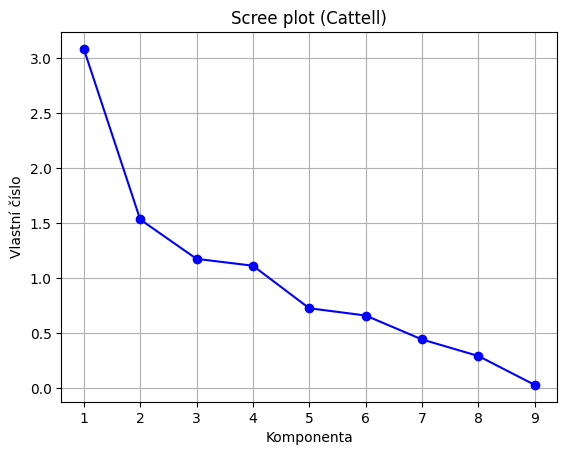

In [ ]:
# Spočítáme procenta vysvětleného rozptylu
var_exp = [(i / sum(eigen_values)) * 100 for i in sorted(eigen_values, reverse=True)]
cum_var_exp = np.cumsum(var_exp)

plt.plot(range(1, len(eigen_values) + 1), eigen_values, 'bo-')
plt.title('Scree plot (Cattell)')
plt.xlabel('Komponenta')
plt.ylabel('Vlastní číslo')
plt.grid(True)
plt.show()

Výběr dle požadavku na podíl vysvětleného rozptylu

In [ ]:
# compute simple condition for thresholding number of components by percentage
threshold_percentage = 0.8

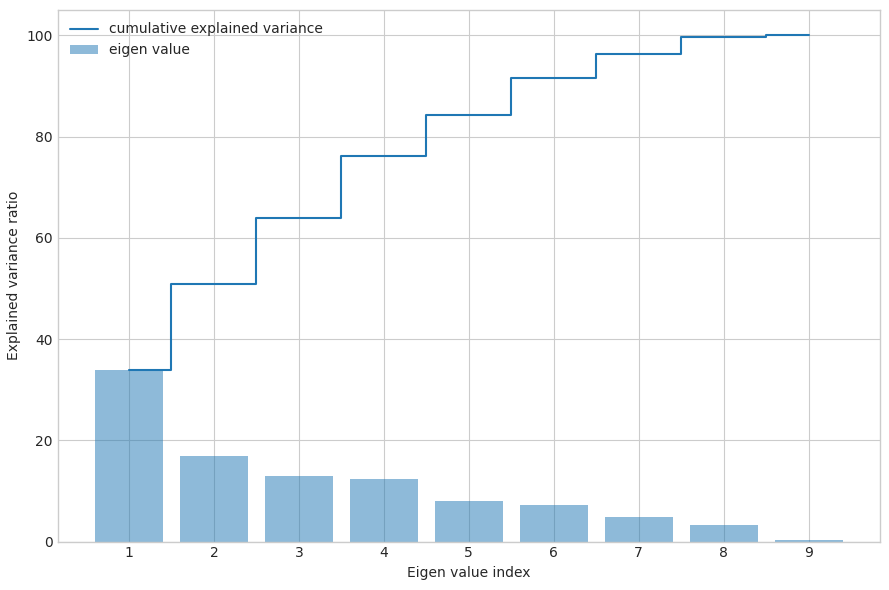

In [ ]:
with plt.style.context('seaborn-v0_8-whitegrid'):
    plt.figure(figsize=(9, 6))

    plt.bar(range(9), var_exp, alpha=0.5, align='center',
            label='eigen value')
    plt.step(range(9), cum_var_exp, where='mid',
             label='cumulative explained variance')
    plt.ylabel('Explained variance ratio')
    plt.xlabel('Eigen value index')
    plt.xticks(range(9),range(1,10))
    plt.legend(loc='best')
    plt.tight_layout()

## Výběr K transformačních vektorů


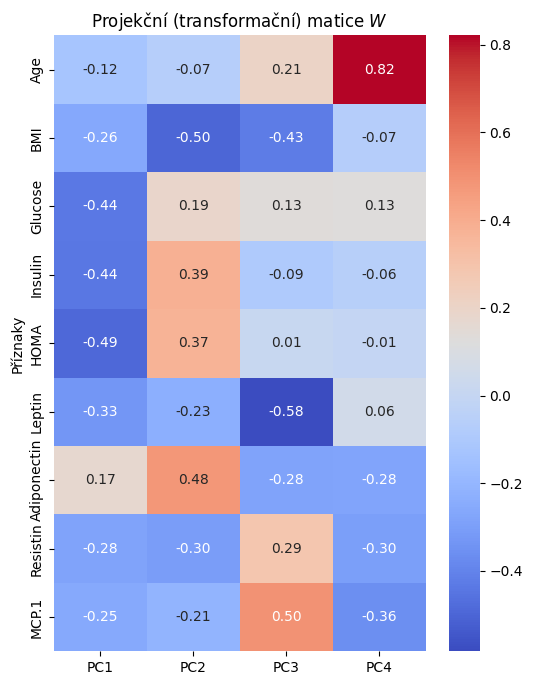

In [ ]:
# create matrix of eigenvectors (transformation m.) of selected components
k = 4  # zvolený počet komponent (např. 2 nebo 4)
W = np.hstack([eigen_pairs[i][1].reshape(-1, 1) for i in range(k)])
W_df = pd.DataFrame(W, index=data_DF.columns, columns=[f'PC{i+1}' for i in range(k)])

plt.figure(figsize=(6, 8))
sns.heatmap(W_df, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Projekční (transformační) matice $W$")
plt.ylabel("Příznaky")
plt.show()

Odpovězte:
1. Které příznaky jsou důležité pro kterou komponentu?
  - Pro danou komponentu jsou nejdůležitější ty příznaky, které v transformační matici (vektoru) dosahují nejvyšších absolutních hodnot vah (tzv. loadings). U první komponenty (PC1) to bývají silně provázané metabolické ukazatele jako BMI, glukóza a inzulin, zatímco PC2 často táhnou věk a počet těhotenství.
2. Jaký význam mají numerické hodnoty komponentní zátěže (absolutní hodnota i znaménko)?
  - Absolutní hodnota vyjadřuje míru důležitosti (váhu), jakou daný příznak přispívá k definici nové komponenty. Znaménko (+ nebo −) určuje směr vazby – proměnné se stejným znaménkem v rámci komponenty korelují pozitivně, zatímco opačná znaménka značí protichůdný vztah.
3. Je možné některé z komponent fyziologicky interpretovat?
  - Ano, komponenty často reprezentují skryté biologické procesy. Například PC1 lze interpretovat jako obecný „metabolicko-diabetický faktor“ (obezita, hladina cukru a inzulinu), zatímco PC2 často představuje „faktor stárnutí a reprodukční zátěže“ (věk a počet těhotenství).

## Výpočet hlavních komponent
* Projekce původních objektů do nového příznakového prostoru pomocí lineární kombinace

In [ ]:
# Projekce původních objektů do nového příznakového prostoru pomocí lineární kombinace
pca_data = np.dot(data_stand, W)

# Převedení do DataFrame pro přehlednost
principal_components_df = pd.DataFrame(pca_data, columns=[f'PC{i+1}' for i in range(k)])

print("Ukázka transformovaných dat (prvních 5 řádků):")
display(principal_components_df.head())

Ukázka transformovaných dat (prvních 5 řádků):


,PC1,PC2,PC3,PC4
0,1.992785,0.125612,0.362869,-0.274120
1,1.328830,0.247930,1.336740,1.894392
2,1.217244,0.992393,0.363065,0.913672
3,1.199203,-0.272409,1.759583,0.271717
4,0.898467,-0.143089,2.019185,1.579261


## Verifikace nezávislosti nově získaných hlavních komponent

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has be

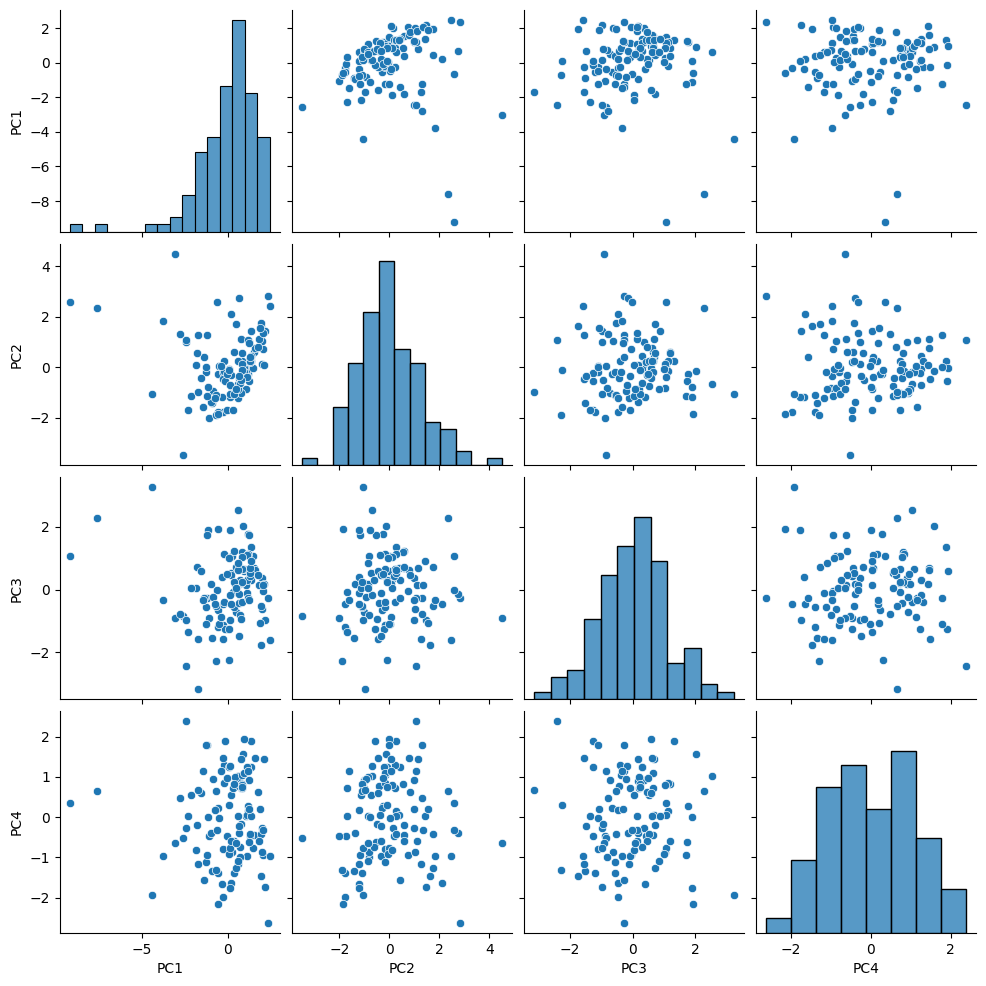

In [ ]:
sns.pairplot(principal_components_df, palette="coolwarm")

     PC1  PC2  PC3  PC4
PC1  1.0  0.0 -0.0  0.0
PC2  0.0  1.0 -0.0  0.0
PC3 -0.0 -0.0  1.0  0.0
PC4  0.0  0.0  0.0  1.0


<Axes: >

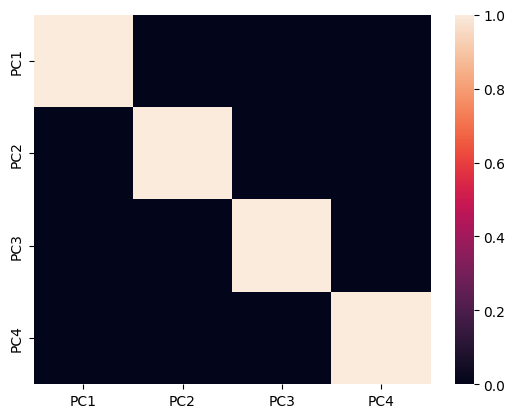

In [ ]:
data_PCA_corr_mat = np.around(principal_components_df.corr())
print(data_PCA_corr_mat)
sns.heatmap(data_PCA_corr_mat)

## Vizuální analýza výstupu PCA
* Biplot - rozptylový diagram komponentního skóre a graf komponentních zátěží
* Vykreslení biplotů pro vybrané dvojice hlavních komponent
*

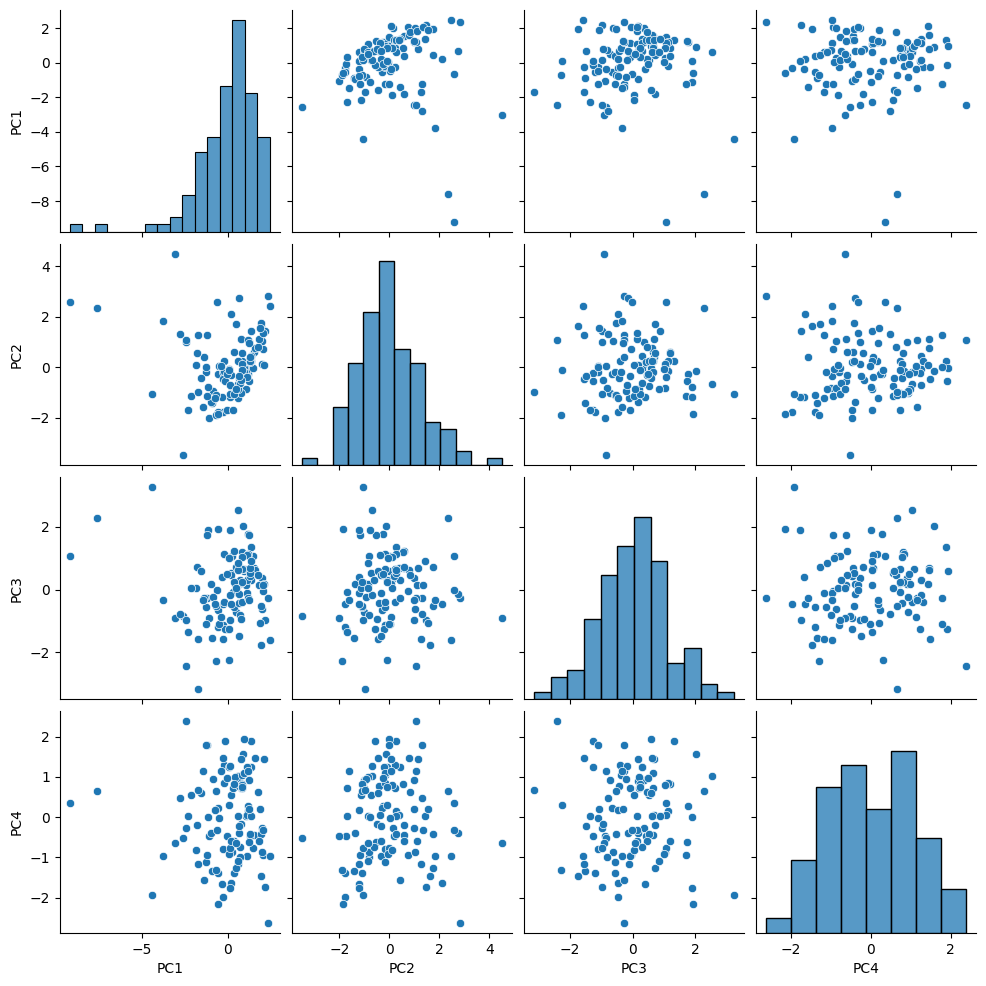

Korelační matice hlavních komponent (měla by být diagonální s 1):
     PC1  PC2  PC3  PC4
PC1  1.0  0.0 -0.0  0.0
PC2  0.0  1.0 -0.0  0.0
PC3 -0.0 -0.0  1.0  0.0
PC4  0.0  0.0  0.0  1.0


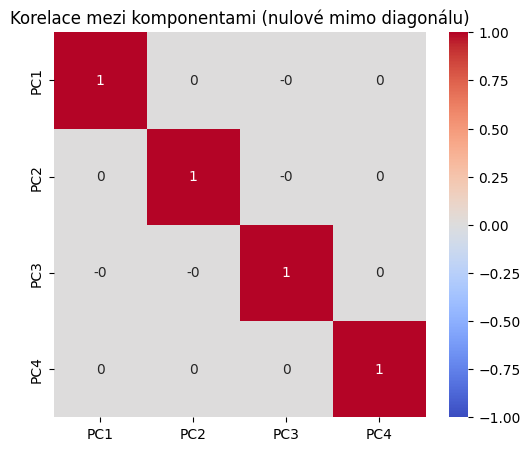

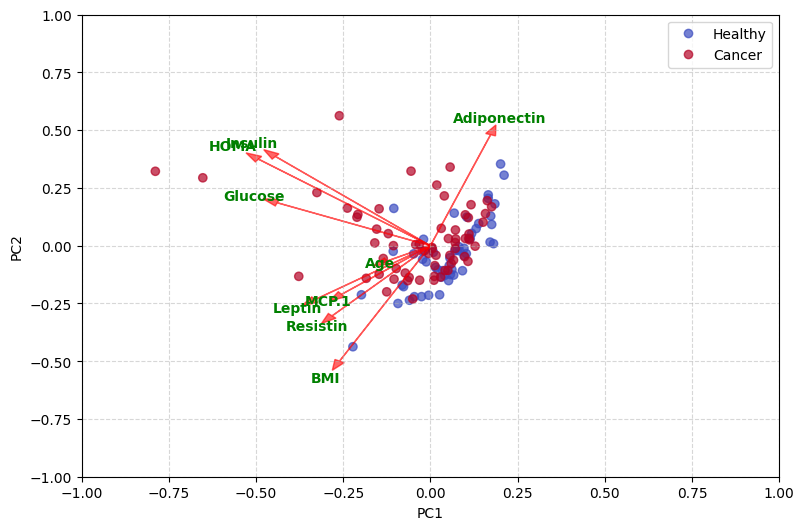

In [ ]:
# 1. Kontrola nekorelovanosti hlavních komponent
sns.pairplot(principal_components_df)
plt.show()

data_PCA_corr_mat = np.around(principal_components_df.corr(), decimals=2)
print("Korelační matice hlavních komponent (měla by být diagonální s 1):")
print(data_PCA_corr_mat)

plt.figure(figsize=(6, 5))
sns.heatmap(data_PCA_corr_mat, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelace mezi komponentami (nulové mimo diagonálu)")
plt.show()

# 2. Projekce a definice funkce Biplot
data_PCA_array = np.dot(data_stand, projection_matrix_v)

def biplot(score, coeff, pcax, pcay, labels=None):
    pca1 = pcax - 1
    pca2 = pcay - 1
    xs = score[:, pca1]
    ys = score[:, pca2]
    n = coeff.shape[0]

    # Normalizace skóre do rozsahu <-1, 1> pro srovnání s vektory
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())

    plt.figure(figsize=(9, 6))
    scatter = plt.scatter(xs * scalex, ys * scaley, c=data_DF_orig["Classification"], cmap="coolwarm", alpha=0.7)

    for i in range(n):
        # Vykreslení šipek příznaků (komponentních zátěží)
        plt.arrow(0, 0, coeff[i, pca1], coeff[i, pca2], color='r', alpha=0.6, head_width=0.03)
        lbl = f"Var{i+1}" if labels is None else labels[i]
        plt.text(coeff[i, pca1] * 1.15, coeff[i, pca2] * 1.15, lbl, color='g', ha='center', va='center', fontweight='bold')

    plt.xlim(-1, 1)
    plt.ylim(-1, 1)
    plt.xlabel(f"PC{pcax}")
    plt.ylabel(f"PC{pcay}")
    plt.legend(handles=scatter.legend_elements()[0], labels=["Healthy", "Cancer"])
    plt.grid(True, linestyle="--", alpha=0.5)

# Vykreslení biplotu pro PC1 a PC4 (případně změň na 1 a 2)
biplot(data_PCA_array, projection_matrix_v, 1, 2, list(data_DF.columns))
plt.show()

Odpovězte:
1. Popište a interpretujte získaný graf (biplot).
2. Které z příznaků jsou korelované mezi sebou?
3. Které příznaky je významně podílí na jednotlivých komponentách?
4. Jaká je interakce mezi příznaky a objekty?
5. Odpovídají výsledky předpokladům z prvotní analýzy?

## Vytvoření predikčního modelu pomocí logistické regrese
1. Na základě komponentních koeficientů PCA vyberte pět původních příznaků, které by podle vás mohly být užitečné pro klasifikaci zdravých a nemocných pacientů.

2. Vytvořte model logistické regrese s vybranými příznaky. Data rozdělte na trénovací a testovací množinu a proveďte standardizaci.

3. Vyhodnoťte klasifikační úspěšnost na trénovacích a testovacích datech. Interpretujte konfuzní matici. Jaký je rozdíl mezi trénovací a testovací úspěšností?

4. Vytvořte druhý model, který místo vybraných původních příznaků využívá první čtyři hlavní komponenty PCA.

5. Vytvořte třetí model využívající všech devět původních příznaků.

6. Porovnejte výsledky všech tří modelů. Který dosahuje nejlepší klasifikační úspěšnosti na testovacích datech?

7. Znamená vysoký podíl vysvětleného rozptylu PCA automaticky vysokou klasifikační úspěšnost? Proč ano, nebo proč ne?


 Vybrané příznaky
Training accuracy: 0.642
Test accuracy: 0.657


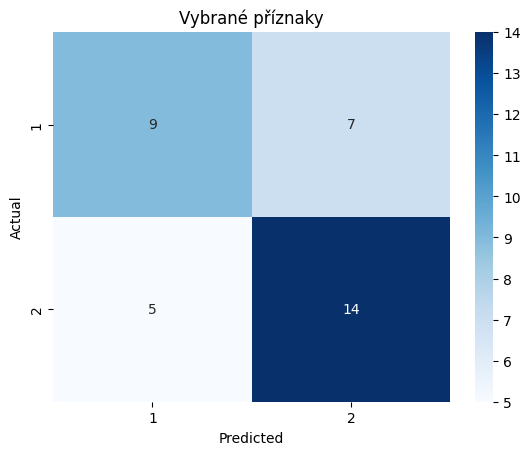


 PCA (4 komponenty)
Training accuracy: 0.667
Test accuracy: 0.743


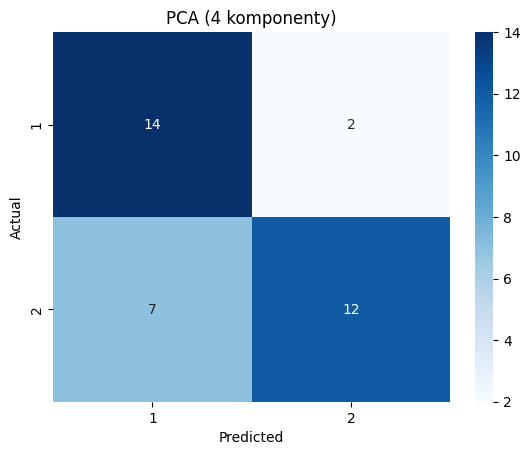


 Všechny příznaky
Training accuracy: 0.815
Test accuracy: 0.8


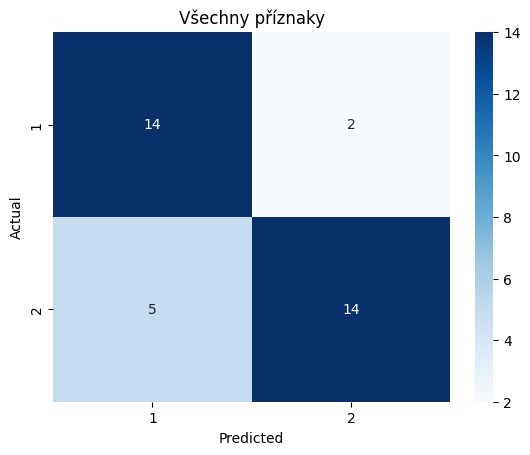

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Původní příznaky a klasifikace
X = data_DF
y = data_DF_orig["Classification"]

# Rozdělení dat (stejné pro všechny modely)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 1. Vybrané příznaky
selected_features = ["HOMA", "BMI", "Adiponectin", "Age", "MCP.1"]

model_selected = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model_selected.fit(X_train[selected_features], y_train)

# 2. První čtyři hlavní komponenty
model_pca = make_pipeline(
    StandardScaler(),
    PCA(n_components=4),
    LogisticRegression(max_iter=1000)
)

model_pca.fit(X_train, y_train)

# 3. Všechny původní příznaky
model_all = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model_all.fit(X_train, y_train)

# Porovnání
models = {
    "Vybrané příznaky": (model_selected, selected_features),
    "PCA (4 komponenty)": (model_pca, list(X.columns)),
    "Všechny příznaky": (model_all, list(X.columns))
}

for name, (model, features) in models.items():

    train_pred = model.predict(X_train[features])
    test_pred = model.predict(X_test[features])

    print("\n", name)
    print("Training accuracy:",
          round(accuracy_score(y_train, train_pred), 3))
    print("Test accuracy:",
          round(accuracy_score(y_test, test_pred), 3))

    cm = confusion_matrix(y_test, test_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name)
    plt.show()